## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Isaiah De Vera

**Date:** 10/12/26

In [70]:
# Your Phase 1 solution to the problem goes here.

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

2.


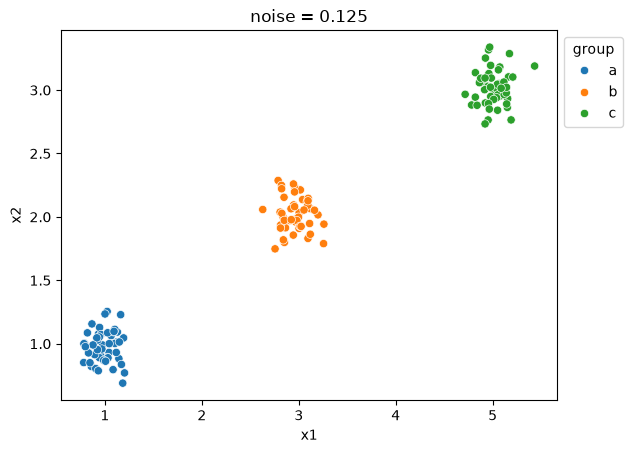

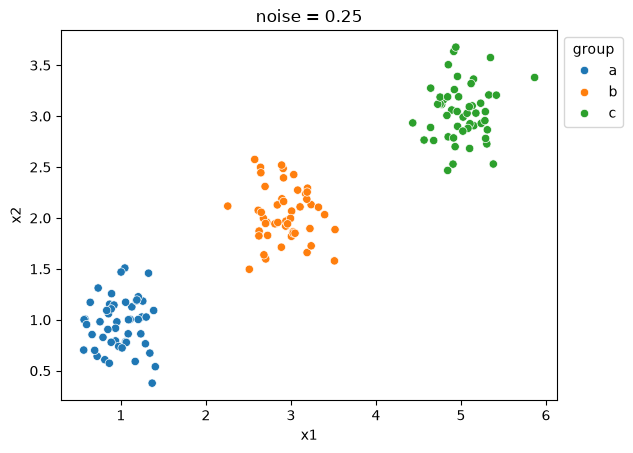

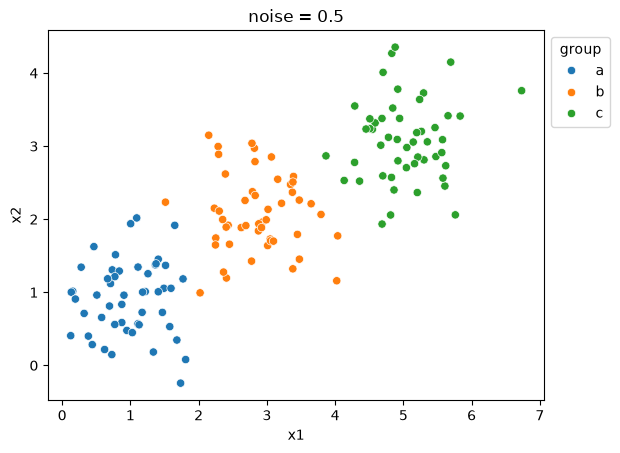

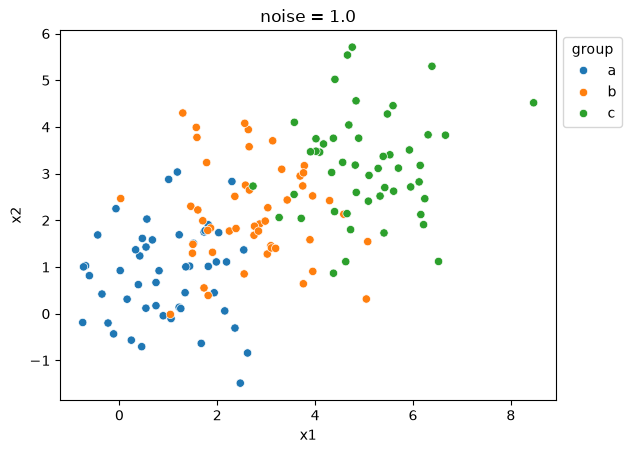

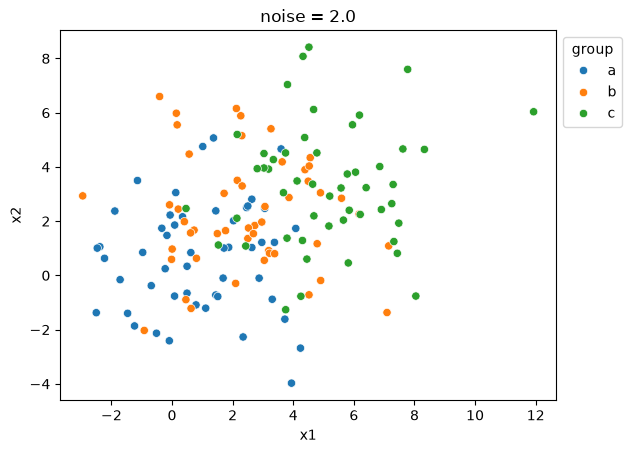

as the noise increases, the visual distinctness of the clusters decreases


In [71]:
print('2.')
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure()
ax = sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title('noise = 0.125')
plt.show()

plt.figure()
ax = sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title('noise = 0.25')
plt.show()

plt.figure()
ax = sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title('noise = 0.5')
plt.show()

plt.figure()
ax = sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title('noise = 1.0')
plt.show()

plt.figure()
ax = sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title('noise = 2.0')
plt.show()

print('as the noise increases, the visual distinctness of the clusters decreases')

Increasing noise makes the scree plot more smooth and curved which makes a clear bend less obvious and makes selecting the defiinitive elbow k more difficult


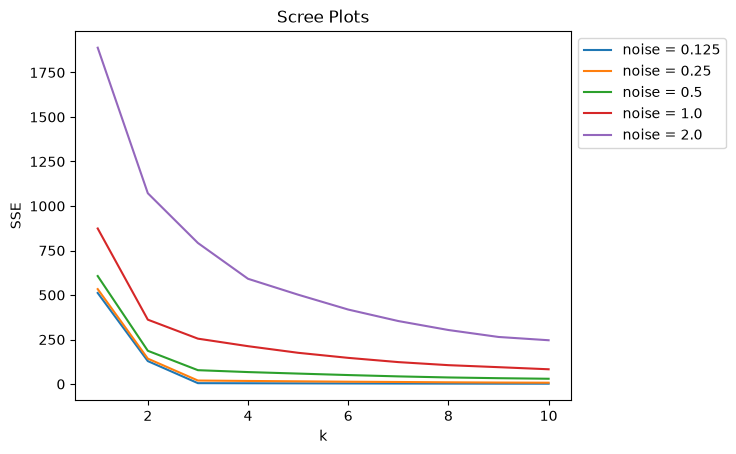

In [72]:
from sklearn.cluster import KMeans

ks = np.arange(1, 11)

def getSSE(d):
    X = d[["x1", "x2"]]
    return [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]

sns.lineplot(x=ks, y=getSSE(df0_125), label="noise = 0.125")
sns.lineplot(x=ks, y=getSSE(df0_25), label="noise = 0.25")
sns.lineplot(x=ks, y=getSSE(df0_5), label="noise = 0.5")
sns.lineplot(x=ks, y=getSSE(df1_0), label="noise = 1.0")
ax = sns.lineplot(x=ks, y=getSSE(df2_0), label="noise = 2.0")

ax.set(title="Scree Plots", xlabel="k", ylabel="SSE")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

print('Increasing noise makes the scree plot more smooth and curved which makes a clear bend less obvious and makes selecting the defiinitive elbow k more difficult')

In [73]:
print('4.\n The elbow measures where the difference in SSE stops decreasing by a large amount, and with condensed clusters, it is easy to spot when all groups have been caught at the right k-value. But with higher noise, it becomes harder to distinguish groups with more overlap, so there is less of a sharp cutoff. In this example, we have 3 groups, and the lower noises have a clear elbow at k = 3, but the higher noise of 2 has a steeper curve and could possible have an elbow at k = 4 instead')

4.
 The elbow measures where the difference in SSE stops decreasing by a large amount, and with condensed clusters, it is easy to spot when all groups have been caught at the right k-value. But with higher noise, it becomes harder to distinguish groups with more overlap, so there is less of a sharp cutoff. In this example, we have 3 groups, and the lower noises have a clear elbow at k = 3, but the higher noise of 2 has a steeper curve and could possible have an elbow at k = 4 instead


In [74]:
print('Q2\n1.')
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df_filtered = df.loc[df['Year'] == 2020]
df_filtered = df_filtered.dropna()
df_filtered.count()


Q2
1.


index                             148
Year                              148
Country                           148
Spending (2020 USD)               148
Percent of GDP                    148
Percent of Government Spending    148
Spending per Capita               148
dtype: int64

2.
['Spending (2020 USD)', 'Spending per Capita']


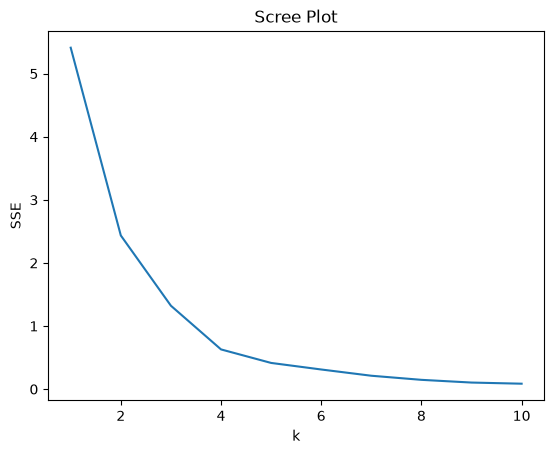

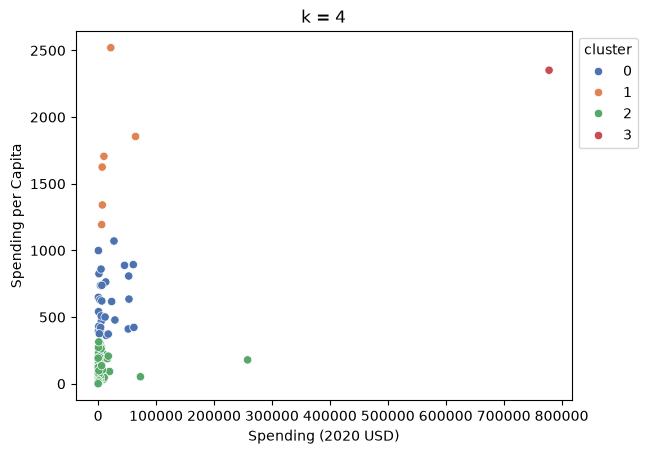

cluster                               0             1              2  \
Spending (2020 USD) count     30.000000      6.000000     111.000000   
                    mean   17077.591354  19443.362047    4859.185065   
                    std    20583.053357  22861.507114   25405.739131   
                    min      405.790494   6095.708713       8.622460   
                    25%     2294.039665   7023.251766     130.010211   
                    50%     5857.060906   8624.225729     382.464677   
                    75%    26296.001003  18857.070183    2297.032353   
                    max    61712.537169  64558.400000  257973.429834   
Spending per Capita count     30.000000      6.000000     111.000000   
                    mean     607.478618   1706.721916      80.061470   
                    std      206.928757    466.375705      83.501824   
                    min      362.467076   1193.598730       0.580129   
                    25%      422.208252   1412.083201      14.88

In [75]:
print('2.')

cols = ['Spending (2020 USD)', 'Spending per Capita']

#normalization
X = (df_filtered[cols] - df_filtered[cols].min()) / (df_filtered[cols].max() - df_filtered[cols].min())
print(X.columns.tolist())

#scree plot
sse = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
    for k in ks
]

ax = sns.lineplot(x=ks, y=sse)
ax.set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

#scatterplot
k = 4

km = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
d2 = df_filtered.copy()
d2["cluster"] = km.labels_

plt.figure()
ax = sns.scatterplot(data=d2, x=cols[0], y=cols[1], hue="cluster", palette="deep")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f"k = {k}")
plt.show()

#describe table conditional on cluster
print(d2.groupby("cluster")[cols].describe().T)

#who is in each cluster
for c, countries in d2.groupby("cluster")["Country"]:
    print(f"\nCluster {c} ({len(countries)} countries):")
    print(", ".join(countries))


In [76]:
print('2. (cont)')
print(
"""
The clusters are mainly split by Spending by capita. Cluster 0 had 30 countries and an average of $607 per person. Cluster 1 had 6 countries and an average of $1707 per person. Cluster 2 had 111 countries and an average of $80 per person. Cluster 3 had 1 country an average of $2352 per person. Total spending did not separate groups that much since cluster 0 had an average of 17077 and cluster 1 had an average of 19443 which are very close
The United States is in cluster 3
Cluster 0 is a lot of wealthy developed countries (Australia, Canada, France, Japan, UK)
Cluster 1 has smaller high capita countries (Norway, Saudi Arabi, Singapore)
Cluster 2 has a lot of poorer, smaller, less developed countries (Afghanistan, Chile, El Salvador, Geprgia, Kazakhstan)
Cluster 2 also has India and China which has such a large population that the per capita spending is so small
Cluster 3 contains only the US
"""
)

2. (cont)

The clusters are mainly split by Spending by capita. Cluster 0 had 30 countries and an average of $607 per person. Cluster 1 had 6 countries and an average of $1707 per person. Cluster 2 had 111 countries and an average of $80 per person. Cluster 3 had 1 country an average of $2352 per person. Total spending did not separate groups that much since cluster 0 had an average of 17077 and cluster 1 had an average of 19443 which are very close
The United States is in cluster 3
Cluster 0 is a lot of wealthy developed countries (Australia, Canada, France, Japan, UK)
Cluster 1 has smaller high capita countries (Norway, Saudi Arabi, Singapore)
Cluster 2 has a lot of poorer, smaller, less developed countries (Afghanistan, Chile, El Salvador, Geprgia, Kazakhstan)
Cluster 2 also has India and China which has such a large population that the per capita spending is so small
Cluster 3 contains only the US



3.
['Percent of Government Spending', 'Percent of GDP']


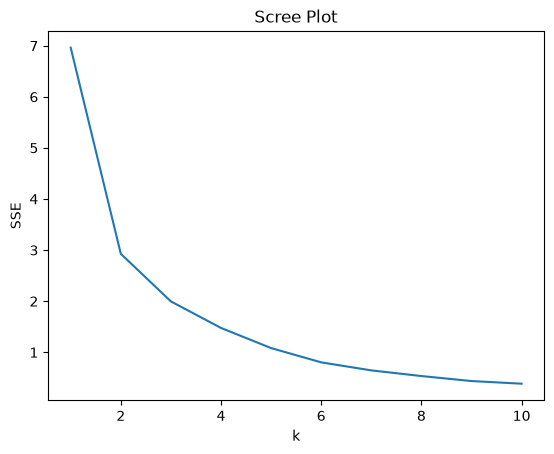

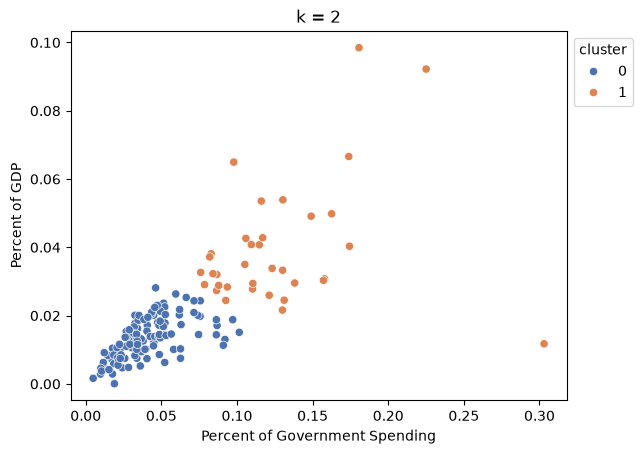

cluster                                        0          1
Percent of Government Spending count  113.000000  35.000000
                               mean     0.041394   0.126456
                               std      0.020681   0.046209
                               min      0.004896   0.076005
                               25%      0.026783   0.093093
                               50%      0.038486   0.116052
                               75%      0.051496   0.143584
                               max      0.101501   0.303027
Percent of GDP                 count  113.000000  35.000000
                               mean     0.013481   0.039433
                               std      0.005966   0.018179
                               min      0.000054   0.011742
                               25%      0.009147   0.028962
                               50%      0.013631   0.033281
                               75%      0.017830   0.042722
                               max      

In [77]:
print('3.')

cols = ['Percent of Government Spending', 'Percent of GDP']

#normalization
X = (df_filtered[cols] - df_filtered[cols].min()) / (df_filtered[cols].max() - df_filtered[cols].min())
print(X.columns.tolist())

#scree plot
sse = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
    for k in ks
]

ax = sns.lineplot(x=ks, y=sse)
ax.set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

#scatterplot
k = 2

km = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
d3 = df_filtered.copy()
d3["cluster"] = km.labels_

plt.figure()
ax = sns.scatterplot(data=d3, x=cols[0], y=cols[1], hue="cluster", palette="deep")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f"k = {k}")
plt.show()

#describe table conditional on cluster
print(d3.groupby("cluster")[cols].describe().T)

#who is in each cluster
for c, countries in d3.groupby("cluster")["Country"]:
    print(f"\nCluster {c} ({len(countries)} countries):")
    print(", ".join(countries))

#United States
print(d3.loc[d3["Country"].str.contains("United States"), cols + ["cluster"]])

In [78]:
print('3. (cont)')
print(
"""
Cluster 0 has a lower Percent of Government Spending of 0.04 while Cluster 1 has a Percent of Government Spending of 0.12
Cluster 0 also has a lower Percent of GDP of 0.013 while Cluster 1 has a Percent of GDP of 0.039
The United States is in cluster 1
Cluster 0 has low-burden countries that spend less on military (Austrlaia, Canada, Denmark)
Cluster 1 has high-burden countries that spend more on military (Israel, Russia, United States)
"""
)

3. (cont)

Cluster 0 has a lower Percent of Government Spending of 0.04 while Cluster 1 has a Percent of Government Spending of 0.12
Cluster 0 also has a lower Percent of GDP of 0.013 while Cluster 1 has a Percent of GDP of 0.039
The United States is in cluster 1
Cluster 0 has low-burden countries that spend less on military (Austrlaia, Canada, Denmark)
Cluster 1 has high-burden countries that spend more on military (Israel, Russia, United States)



4.
['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']


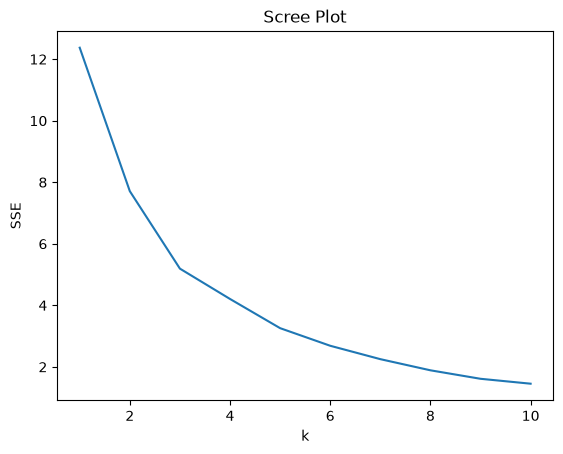

cluster                                           0             1  \
Spending (2020 USD)            count     111.000000     31.000000   
                               mean     7086.472777   8786.086602   
                               std     26479.379918  17901.909108   
                               min         8.622460    162.373364   
                               25%       130.010211    467.787851   
                               50%       567.650747   1404.787234   
                               75%      3910.107493   7739.166193   
                               max    257973.429834  72937.064048   
Spending per Capita            count     111.000000     31.000000   
                               mean      196.926833    212.689100   
                               std       267.788506    257.841988   
                               min         0.580129     18.297119   
                               25%        14.880549     46.485917   
                               50%

In [79]:
print('4.')

cols = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']

#normalization
X = (df_filtered[cols] - df_filtered[cols].min()) / (df_filtered[cols].max() - df_filtered[cols].min())
print(X.columns.tolist())

#scree plot
sse = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
    for k in ks
]

ax = sns.lineplot(x=ks, y=sse)
ax.set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

k = 3

km = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
d4 = df_filtered.copy()
d4["cluster"] = km.labels_

#describe table conditional on cluster
print(d4.groupby("cluster")[cols].describe().T)

#who is in each cluster
for c, countries in d4.groupby("cluster")["Country"]:
    print(f"\nCluster {c} ({len(countries)} countries):")
    print(", ".join(countries))

#United States
print(d4.loc[d4["Country"].str.contains("United States"), cols + ["cluster"]])

#compare to parts 2 and 3
print(pd.crosstab(d2["cluster"], d4["cluster"]))
print(pd.crosstab(d3["cluster"], d4["cluster"]))

In [80]:
print('5.')
print('Yes, k-means found meaningful patterns: total spending, per capita spending and military burden capture different things, so the clusters grouped countries by size and wealth in part 2 but by security environment in part 3 (for example, China and India both have large totals but fall in the low- and high-burden groups respectively), while part 4 was mostly the burden split with a small group carved out. However, the results depend on the choices made, since the US outlier compressed the scaling on total spending and the scree elbows were subjective, and the clusters describe patterns without explaining why countries spend what they do.'
)

5.
Yes, k-means found meaningful patterns: total spending, per capita spending and military burden capture different things, so the clusters grouped countries by size and wealth in part 2 but by security environment in part 3 (for example, China and India both have large totals but fall in the low- and high-burden groups respectively), while part 4 was mostly the burden split with a small group carved out. However, the results depend on the choices made, since the US outlier compressed the scaling on total spending and the scree elbows were subjective, and the clusters describe patterns without explaining why countries spend what they do.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** ac0a2945106bdcbb18914ca07d7c9f0d690f7518
- **AI tool and model used:** ChatGPT

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Make the plots easier to interpret. Use consistent axes for the five noise levels so you can compare how much the clusters overlap.
2. Make the cluster results easier to interpret. Use cluster means and country lists, and explain what each cluster represents rather than relying only on cluster numbers.


### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | reject | I think overlapping the graphs would be too cluttered overlapping the different noises would lose clarity |
| 2 | reject | These metrics would be helpful to better understand the data but the assignment does not ask for them |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [81]:
# Your Phase 2 solution to the problem goes here.

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

2.


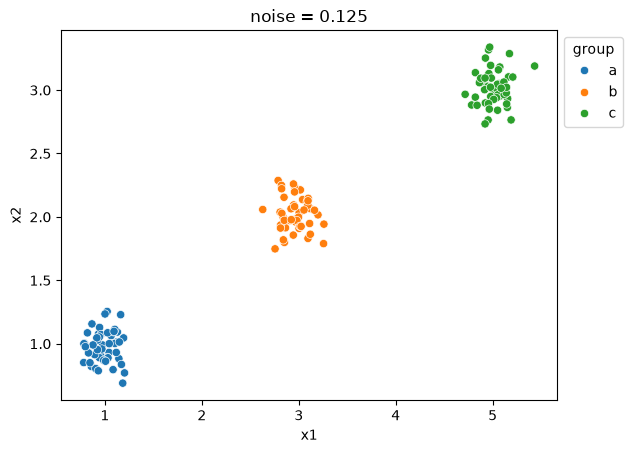

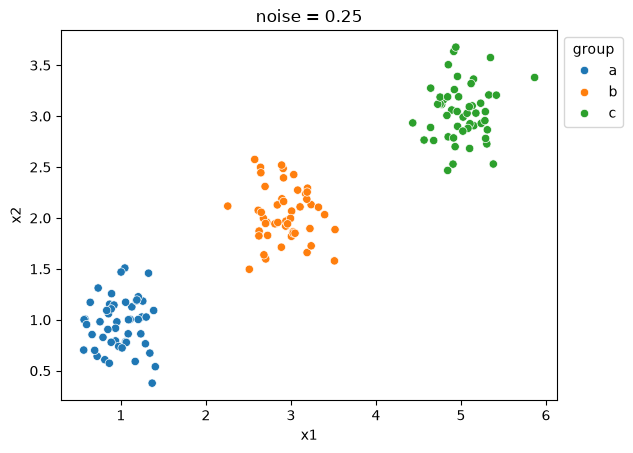

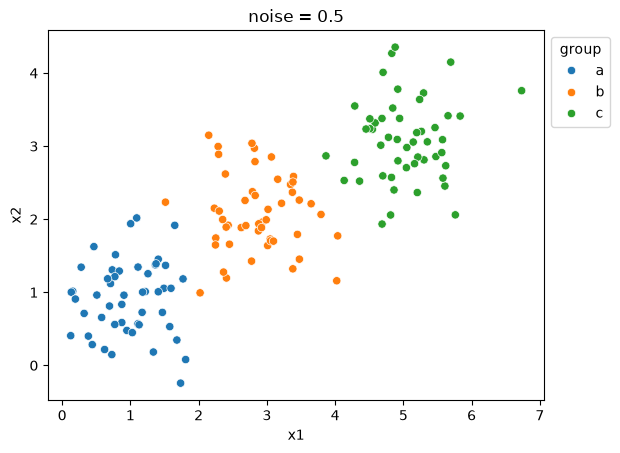

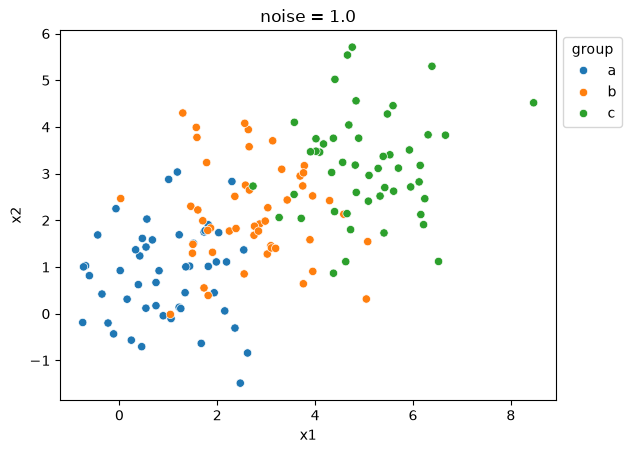

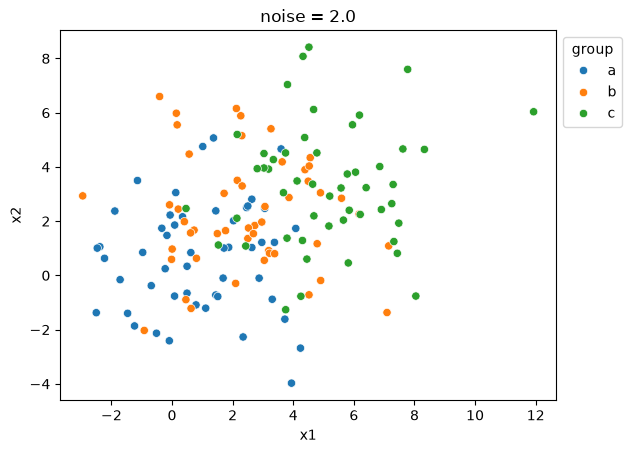

as the noise increases, the visual distinctness of the clusters decreases


In [82]:
print('2.')
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure()
ax = sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title('noise = 0.125')
plt.show()

plt.figure()
ax = sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title('noise = 0.25')
plt.show()

plt.figure()
ax = sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title('noise = 0.5')
plt.show()

plt.figure()
ax = sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title('noise = 1.0')
plt.show()

plt.figure()
ax = sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title('noise = 2.0')
plt.show()

print('as the noise increases, the visual distinctness of the clusters decreases')

Increasing noise makes the scree plot more smooth and curved which makes a clear bend less obvious and makes selecting the defiinitive elbow k more difficult


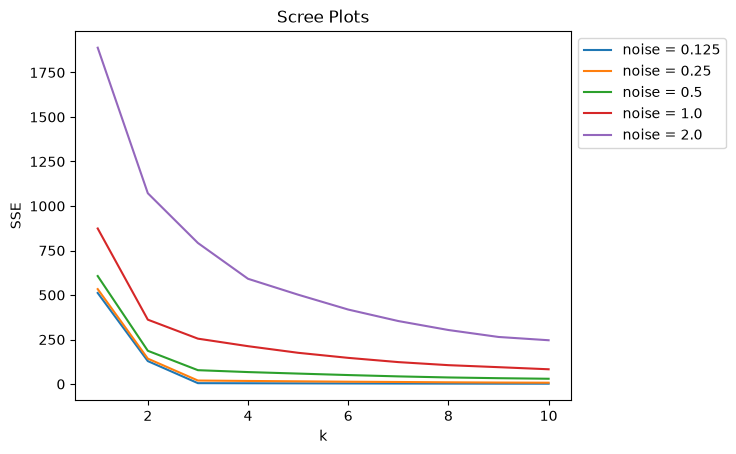

In [83]:
from sklearn.cluster import KMeans

ks = np.arange(1, 11)

def getSSE(d):
    X = d[["x1", "x2"]]
    return [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]

sns.lineplot(x=ks, y=getSSE(df0_125), label="noise = 0.125")
sns.lineplot(x=ks, y=getSSE(df0_25), label="noise = 0.25")
sns.lineplot(x=ks, y=getSSE(df0_5), label="noise = 0.5")
sns.lineplot(x=ks, y=getSSE(df1_0), label="noise = 1.0")
ax = sns.lineplot(x=ks, y=getSSE(df2_0), label="noise = 2.0")

ax.set(title="Scree Plots", xlabel="k", ylabel="SSE")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

print('Increasing noise makes the scree plot more smooth and curved which makes a clear bend less obvious and makes selecting the defiinitive elbow k more difficult')

In [84]:
print('4.\n The elbow measures where the difference in SSE stops decreasing by a large amount, and with condensed clusters, it is easy to spot when all groups have been caught at the right k-value. But with higher noise, it becomes harder to distinguish groups with more overlap, so there is less of a sharp cutoff. In this example, we have 3 groups, and the lower noises have a clear elbow at k = 3, but the higher noise of 2 has a steeper curve and could possible have an elbow at k = 4 instead')

4.
 The elbow measures where the difference in SSE stops decreasing by a large amount, and with condensed clusters, it is easy to spot when all groups have been caught at the right k-value. But with higher noise, it becomes harder to distinguish groups with more overlap, so there is less of a sharp cutoff. In this example, we have 3 groups, and the lower noises have a clear elbow at k = 3, but the higher noise of 2 has a steeper curve and could possible have an elbow at k = 4 instead


In [85]:
print('Q2\n1.')
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df_filtered = df.loc[df['Year'] == 2020]
df_filtered = df_filtered.dropna()
df_filtered.count()


Q2
1.


index                             148
Year                              148
Country                           148
Spending (2020 USD)               148
Percent of GDP                    148
Percent of Government Spending    148
Spending per Capita               148
dtype: int64

2.
['Spending (2020 USD)', 'Spending per Capita']


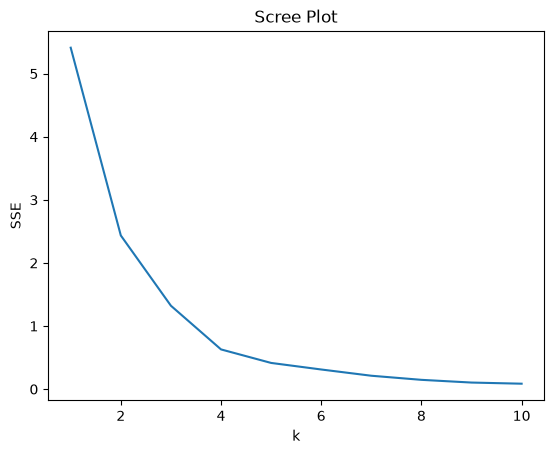

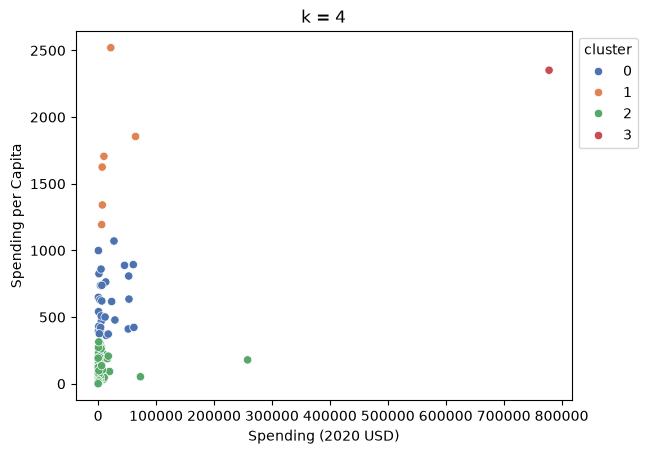

cluster                               0             1              2  \
Spending (2020 USD) count     30.000000      6.000000     111.000000   
                    mean   17077.591354  19443.362047    4859.185065   
                    std    20583.053357  22861.507114   25405.739131   
                    min      405.790494   6095.708713       8.622460   
                    25%     2294.039665   7023.251766     130.010211   
                    50%     5857.060906   8624.225729     382.464677   
                    75%    26296.001003  18857.070183    2297.032353   
                    max    61712.537169  64558.400000  257973.429834   
Spending per Capita count     30.000000      6.000000     111.000000   
                    mean     607.478618   1706.721916      80.061470   
                    std      206.928757    466.375705      83.501824   
                    min      362.467076   1193.598730       0.580129   
                    25%      422.208252   1412.083201      14.88

In [86]:
print('2.')

cols = ['Spending (2020 USD)', 'Spending per Capita']

#normalization
X = (df_filtered[cols] - df_filtered[cols].min()) / (df_filtered[cols].max() - df_filtered[cols].min())
print(X.columns.tolist())

#scree plot
sse = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
    for k in ks
]

ax = sns.lineplot(x=ks, y=sse)
ax.set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

#scatterplot
k = 4

km = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
d2 = df_filtered.copy()
d2["cluster"] = km.labels_

plt.figure()
ax = sns.scatterplot(data=d2, x=cols[0], y=cols[1], hue="cluster", palette="deep")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f"k = {k}")
plt.show()

#describe table conditional on cluster
print(d2.groupby("cluster")[cols].describe().T)

#who is in each cluster
for c, countries in d2.groupby("cluster")["Country"]:
    print(f"\nCluster {c} ({len(countries)} countries):")
    print(", ".join(countries))


In [87]:
print('2. (cont)')
print(
"""
The clusters are mainly split by Spending by capita. Cluster 0 had 30 countries and an average of $607 per person. Cluster 1 had 6 countries and an average of $1707 per person. Cluster 2 had 111 countries and an average of $80 per person. Cluster 3 had 1 country an average of $2352 per person. Total spending did not separate groups that much since cluster 0 had an average of 17077 and cluster 1 had an average of 19443 which are very close
The United States is in cluster 3
Cluster 0 is a lot of wealthy developed countries (Australia, Canada, France, Japan, UK)
Cluster 1 has smaller high capita countries (Norway, Saudi Arabi, Singapore)
Cluster 2 has a lot of poorer, smaller, less developed countries (Afghanistan, Chile, El Salvador, Geprgia, Kazakhstan)
Cluster 2 also has India and China which has such a large population that the per capita spending is so small
Cluster 3 contains only the US
"""
)

2. (cont)

The clusters are mainly split by Spending by capita. Cluster 0 had 30 countries and an average of $607 per person. Cluster 1 had 6 countries and an average of $1707 per person. Cluster 2 had 111 countries and an average of $80 per person. Cluster 3 had 1 country an average of $2352 per person. Total spending did not separate groups that much since cluster 0 had an average of 17077 and cluster 1 had an average of 19443 which are very close
The United States is in cluster 3
Cluster 0 is a lot of wealthy developed countries (Australia, Canada, France, Japan, UK)
Cluster 1 has smaller high capita countries (Norway, Saudi Arabi, Singapore)
Cluster 2 has a lot of poorer, smaller, less developed countries (Afghanistan, Chile, El Salvador, Geprgia, Kazakhstan)
Cluster 2 also has India and China which has such a large population that the per capita spending is so small
Cluster 3 contains only the US



3.
['Percent of Government Spending', 'Percent of GDP']


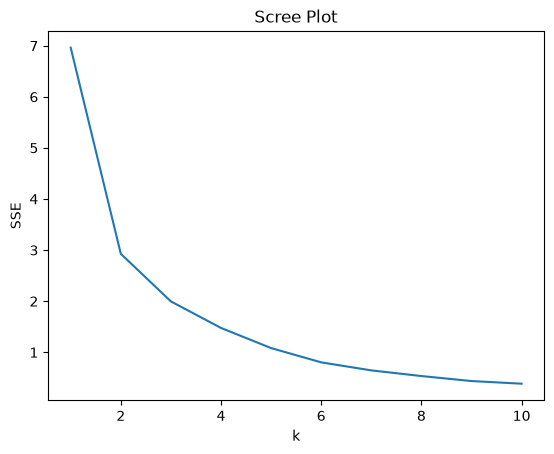

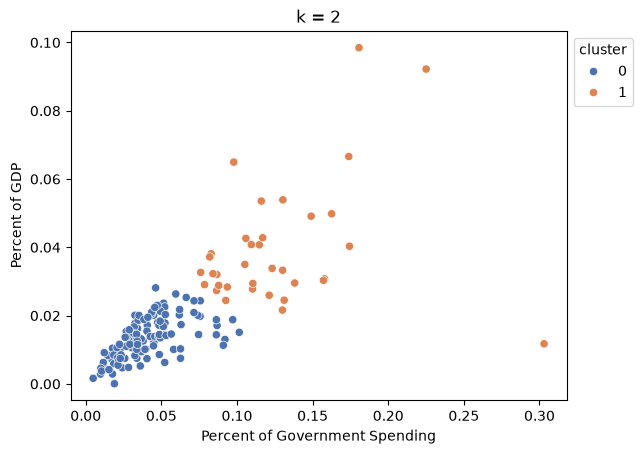

cluster                                        0          1
Percent of Government Spending count  113.000000  35.000000
                               mean     0.041394   0.126456
                               std      0.020681   0.046209
                               min      0.004896   0.076005
                               25%      0.026783   0.093093
                               50%      0.038486   0.116052
                               75%      0.051496   0.143584
                               max      0.101501   0.303027
Percent of GDP                 count  113.000000  35.000000
                               mean     0.013481   0.039433
                               std      0.005966   0.018179
                               min      0.000054   0.011742
                               25%      0.009147   0.028962
                               50%      0.013631   0.033281
                               75%      0.017830   0.042722
                               max      

In [88]:
print('3.')

cols = ['Percent of Government Spending', 'Percent of GDP']

#normalization
X = (df_filtered[cols] - df_filtered[cols].min()) / (df_filtered[cols].max() - df_filtered[cols].min())
print(X.columns.tolist())

#scree plot
sse = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
    for k in ks
]

ax = sns.lineplot(x=ks, y=sse)
ax.set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

#scatterplot
k = 2

km = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
d3 = df_filtered.copy()
d3["cluster"] = km.labels_

plt.figure()
ax = sns.scatterplot(data=d3, x=cols[0], y=cols[1], hue="cluster", palette="deep")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_title(f"k = {k}")
plt.show()

#describe table conditional on cluster
print(d3.groupby("cluster")[cols].describe().T)

#who is in each cluster
for c, countries in d3.groupby("cluster")["Country"]:
    print(f"\nCluster {c} ({len(countries)} countries):")
    print(", ".join(countries))

#United States
print(d3.loc[d3["Country"].str.contains("United States"), cols + ["cluster"]])

In [89]:
print('3. (cont)')
print(
"""
Cluster 0 has a lower Percent of Government Spending of 0.04 while Cluster 1 has a Percent of Government Spending of 0.12
Cluster 0 also has a lower Percent of GDP of 0.013 while Cluster 1 has a Percent of GDP of 0.039
The United States is in cluster 1
Cluster 0 has low-burden countries that spend less on military (Austrlaia, Canada, Denmark)
Cluster 1 has high-burden countries that spend more on military (Israel, Russia, United States)
"""
)

3. (cont)

Cluster 0 has a lower Percent of Government Spending of 0.04 while Cluster 1 has a Percent of Government Spending of 0.12
Cluster 0 also has a lower Percent of GDP of 0.013 while Cluster 1 has a Percent of GDP of 0.039
The United States is in cluster 1
Cluster 0 has low-burden countries that spend less on military (Austrlaia, Canada, Denmark)
Cluster 1 has high-burden countries that spend more on military (Israel, Russia, United States)



4.
['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']


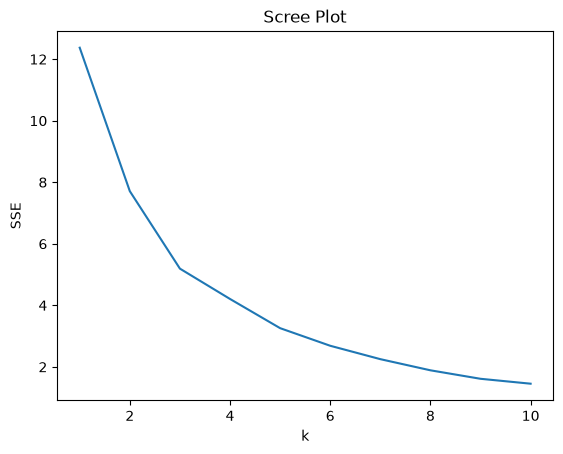

cluster                                           0             1  \
Spending (2020 USD)            count     111.000000     31.000000   
                               mean     7086.472777   8786.086602   
                               std     26479.379918  17901.909108   
                               min         8.622460    162.373364   
                               25%       130.010211    467.787851   
                               50%       567.650747   1404.787234   
                               75%      3910.107493   7739.166193   
                               max    257973.429834  72937.064048   
Spending per Capita            count     111.000000     31.000000   
                               mean      196.926833    212.689100   
                               std       267.788506    257.841988   
                               min         0.580129     18.297119   
                               25%        14.880549     46.485917   
                               50%

In [90]:
print('4.')

cols = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']

#normalization
X = (df_filtered[cols] - df_filtered[cols].min()) / (df_filtered[cols].max() - df_filtered[cols].min())
print(X.columns.tolist())

#scree plot
sse = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_
    for k in ks
]

ax = sns.lineplot(x=ks, y=sse)
ax.set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

k = 3

km = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
d4 = df_filtered.copy()
d4["cluster"] = km.labels_

#describe table conditional on cluster
print(d4.groupby("cluster")[cols].describe().T)

#who is in each cluster
for c, countries in d4.groupby("cluster")["Country"]:
    print(f"\nCluster {c} ({len(countries)} countries):")
    print(", ".join(countries))

#United States
print(d4.loc[d4["Country"].str.contains("United States"), cols + ["cluster"]])

#compare to parts 2 and 3
print(pd.crosstab(d2["cluster"], d4["cluster"]))
print(pd.crosstab(d3["cluster"], d4["cluster"]))

In [91]:
print('5.')
print('Yes, k-means found meaningful patterns: total spending, per capita spending and military burden capture different things, so the clusters grouped countries by size and wealth in part 2 but by security environment in part 3 (for example, China and India both have large totals but fall in the low- and high-burden groups respectively), while part 4 was mostly the burden split with a small group carved out. However, the results depend on the choices made, since the US outlier compressed the scaling on total spending and the scree elbows were subjective, and the clusters describe patterns without explaining why countries spend what they do.'
)

5.
Yes, k-means found meaningful patterns: total spending, per capita spending and military burden capture different things, so the clusters grouped countries by size and wealth in part 2 but by security environment in part 3 (for example, China and India both have large totals but fall in the low- and high-burden groups respectively), while part 4 was mostly the burden split with a small group carved out. However, the results depend on the choices made, since the US outlier compressed the scaling on total spending and the scree elbows were subjective, and the clusters describe patterns without explaining why countries spend what they do.


### *Reflection on AI assistance
In your own words without generative AI.

The AI was not very helpful for this specific assignment. The first suggestion it gave me was trying to help but it really made it more complicated. Combining the noises onto a single graph would have created so much visual clutter that the pattern would have been hard to see. The other suggestion was not very helpful since it was giving suggestions outside the scope of the assignment. This is a limitation of the AI since it does not know the exact requirements given. It does not know what was asked for so it tries to help by suggesting more things that are not necessarily needed. 